In [1]:
import os
import tarfile
import sklearn
from six.moves import urllib

In [2]:
DOWNLOAD_ROOT = "https://raw.githubusercontent.com/ageron/handson-ml2/master/"
HOUSING_PATH = os.path.join("datasets", "housing")
HOUSING_URL = DOWNLOAD_ROOT + "datasets/housing/housing.tgz"

def fetch_housing_data(housing_url = HOUSING_URL, housing_path = HOUSING_PATH):
    if not os.path.isdir(housing_path):
        os.makedirs(housing_path)

    tgz_path = os.path.join(housing_path, "housing.tgz")
    urllib.request.urlretrieve(housing_url, tgz_path)
    housing_tgz = tarfile.open(tgz_path) 
    housing_tgz.extractall(path=housing_path)
    housing_tgz.close() 


In [3]:
import pandas as pd

def load_housing_data(housing_path=HOUSING_PATH):
    csv_path = os.path.join(housing_path, "housing.csv")
    return pd.read_csv(csv_path)

In [4]:
housing = load_housing_data()
housing.head()
# # housing.info()
# # housing["ocean_proximity"].value_counts()
# housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


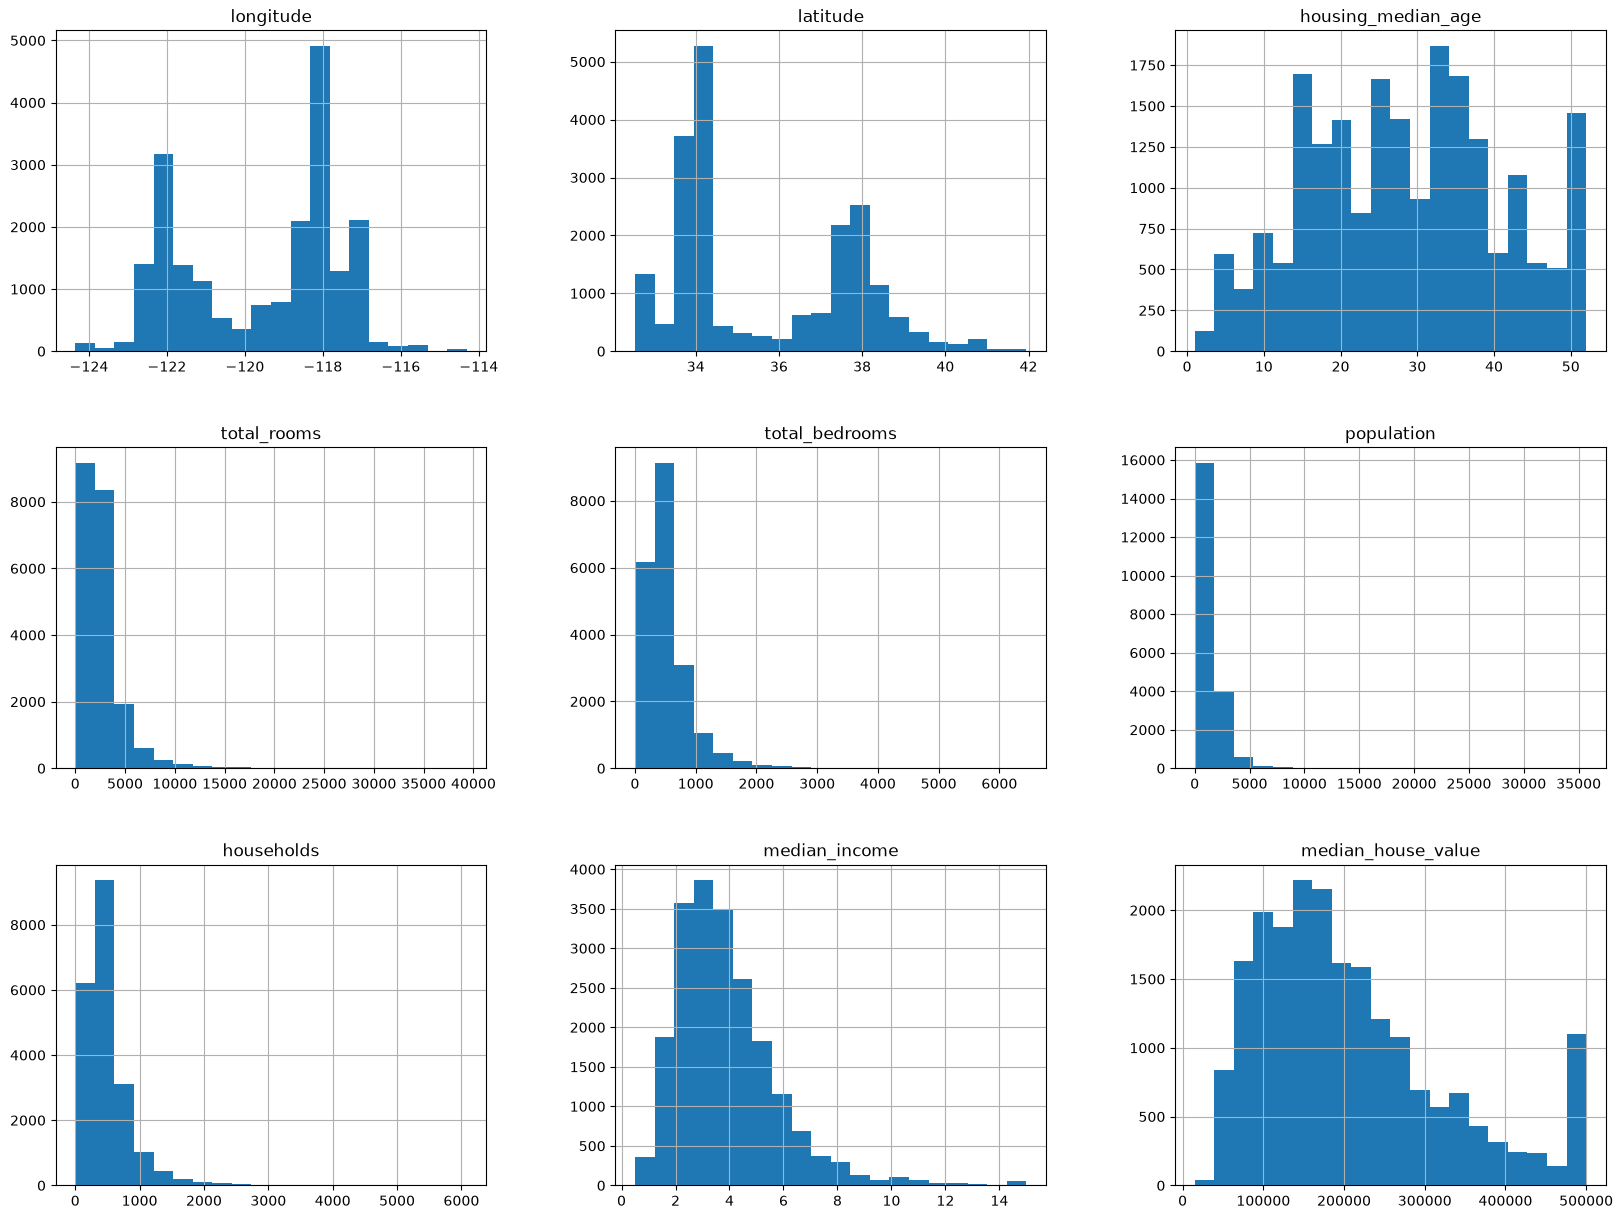

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt
housing.hist(bins=20, figsize=(20,15))
plt.show()

In [6]:
import numpy as np

def split_train_test(data, ratio):
    shuffled_indices = np.random.permutation(len(data))
    test_set_size = int(len(data) * ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

In [7]:
train_set, test_set = split_train_test(housing, 0.2)


# len(test_set)|
# len(train_set)

In [8]:
from zlib import crc32
def test_set_check(identifier, test_ratio):
    return crc32(np.int64(identifier)) < test_ratio * 2**32

def split_train_test_by_id(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: test_set_check(id_, test_ratio))
    return data.iloc[~in_test_set], data.iloc[in_test_set]

In [9]:
housing_with_id = housing.reset_index()
train_set, test_set = split_train_test_by_id(housing_with_id, 0.2, "index")
print(test_set)

       index  longitude  latitude  housing_median_age  total_rooms  \
2          2    -122.24     37.85                52.0       1467.0   
5          5    -122.25     37.85                52.0        919.0   
12        12    -122.26     37.85                52.0       2491.0   
16        16    -122.27     37.85                52.0       1966.0   
23        23    -122.27     37.84                52.0       1688.0   
...      ...        ...       ...                 ...          ...   
20615  20615    -121.54     39.08                23.0       1076.0   
20617  20617    -121.53     39.06                20.0        561.0   
20622  20622    -121.44     39.00                20.0        755.0   
20626  20626    -121.43     39.18                36.0       1124.0   
20629  20629    -121.39     39.12                28.0      10035.0   

       total_bedrooms  population  households  median_income  \
2               190.0       496.0       177.0         7.2574   
5               213.0       413

In [10]:
housing["income_cat"] = pd.cut(housing["median_income"], bins = [0., 1.5, 3.0, 4.5, 6, np.inf], labels = [1, 2, 3, 4, 5])

<Axes: >

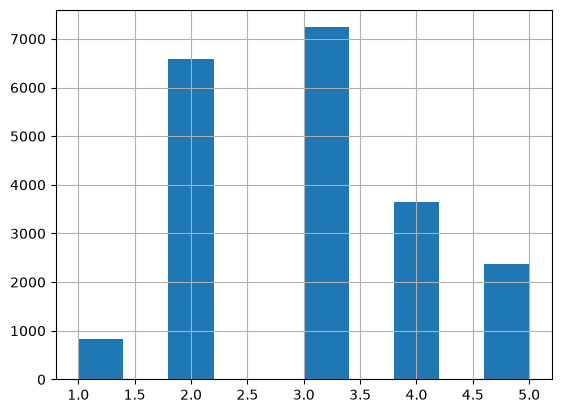

In [11]:
housing["income_cat"].hist()

In [12]:
from sklearn.model_selection import StratifiedShuffleSplit
split = StratifiedShuffleSplit(n_splits = 1, test_size = 0.2, random_state = 42)
for train_index, test_index in split.split(housing, housing["income_cat"]):
    strat_train_set = housing.loc[train_index]
    strat_test_set = housing.loc[test_index]


strat_test_set["income_cat"].value_counts()/len(strat_test_set)


income_cat
3    0.350533
2    0.318798
4    0.176357
5    0.114341
1    0.039971
Name: count, dtype: float64

In [13]:
for set_ in (strat_train_set,strat_test_set):
    set_.drop("income_cat", axis = 1, inplace =True)


In [14]:
housing = strat_train_set.copy()

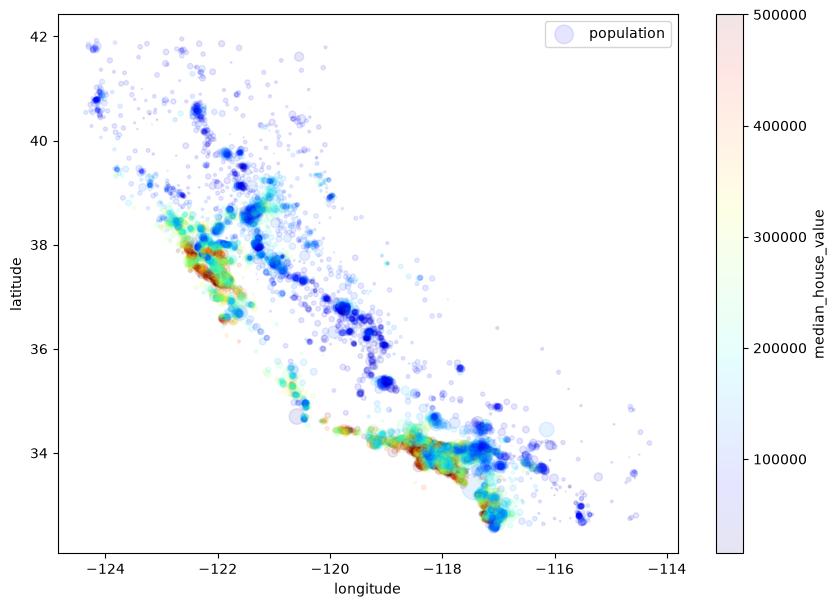

In [15]:
housing.plot(kind="scatter", x = "longitude", y = "latitude", alpha = 0.1,
            s = housing["population"]/100, label = "population", figsize = (10,7),
            c = "median_house_value", cmap = plt.get_cmap("jet"), colorbar =True)
plt.legend()

In [16]:
corr_matrix = housing.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.687151
total_rooms           0.135140
housing_median_age    0.114146
households            0.064590
total_bedrooms        0.047781
population           -0.026882
longitude            -0.047466
latitude             -0.142673
Name: median_house_value, dtype: float64

array([[<Axes: xlabel='median_house_value', ylabel='median_house_value'>,
        <Axes: xlabel='median_income', ylabel='median_house_value'>,
        <Axes: xlabel='total_rooms', ylabel='median_house_value'>,
        <Axes: xlabel='housing_median_age', ylabel='median_house_value'>],
       [<Axes: xlabel='median_house_value', ylabel='median_income'>,
        <Axes: xlabel='median_income', ylabel='median_income'>,
        <Axes: xlabel='total_rooms', ylabel='median_income'>,
        <Axes: xlabel='housing_median_age', ylabel='median_income'>],
       [<Axes: xlabel='median_house_value', ylabel='total_rooms'>,
        <Axes: xlabel='median_income', ylabel='total_rooms'>,
        <Axes: xlabel='total_rooms', ylabel='total_rooms'>,
        <Axes: xlabel='housing_median_age', ylabel='total_rooms'>],
       [<Axes: xlabel='median_house_value', ylabel='housing_median_age'>,
        <Axes: xlabel='median_income', ylabel='housing_median_age'>,
        <Axes: xlabel='total_rooms', ylabel='housi

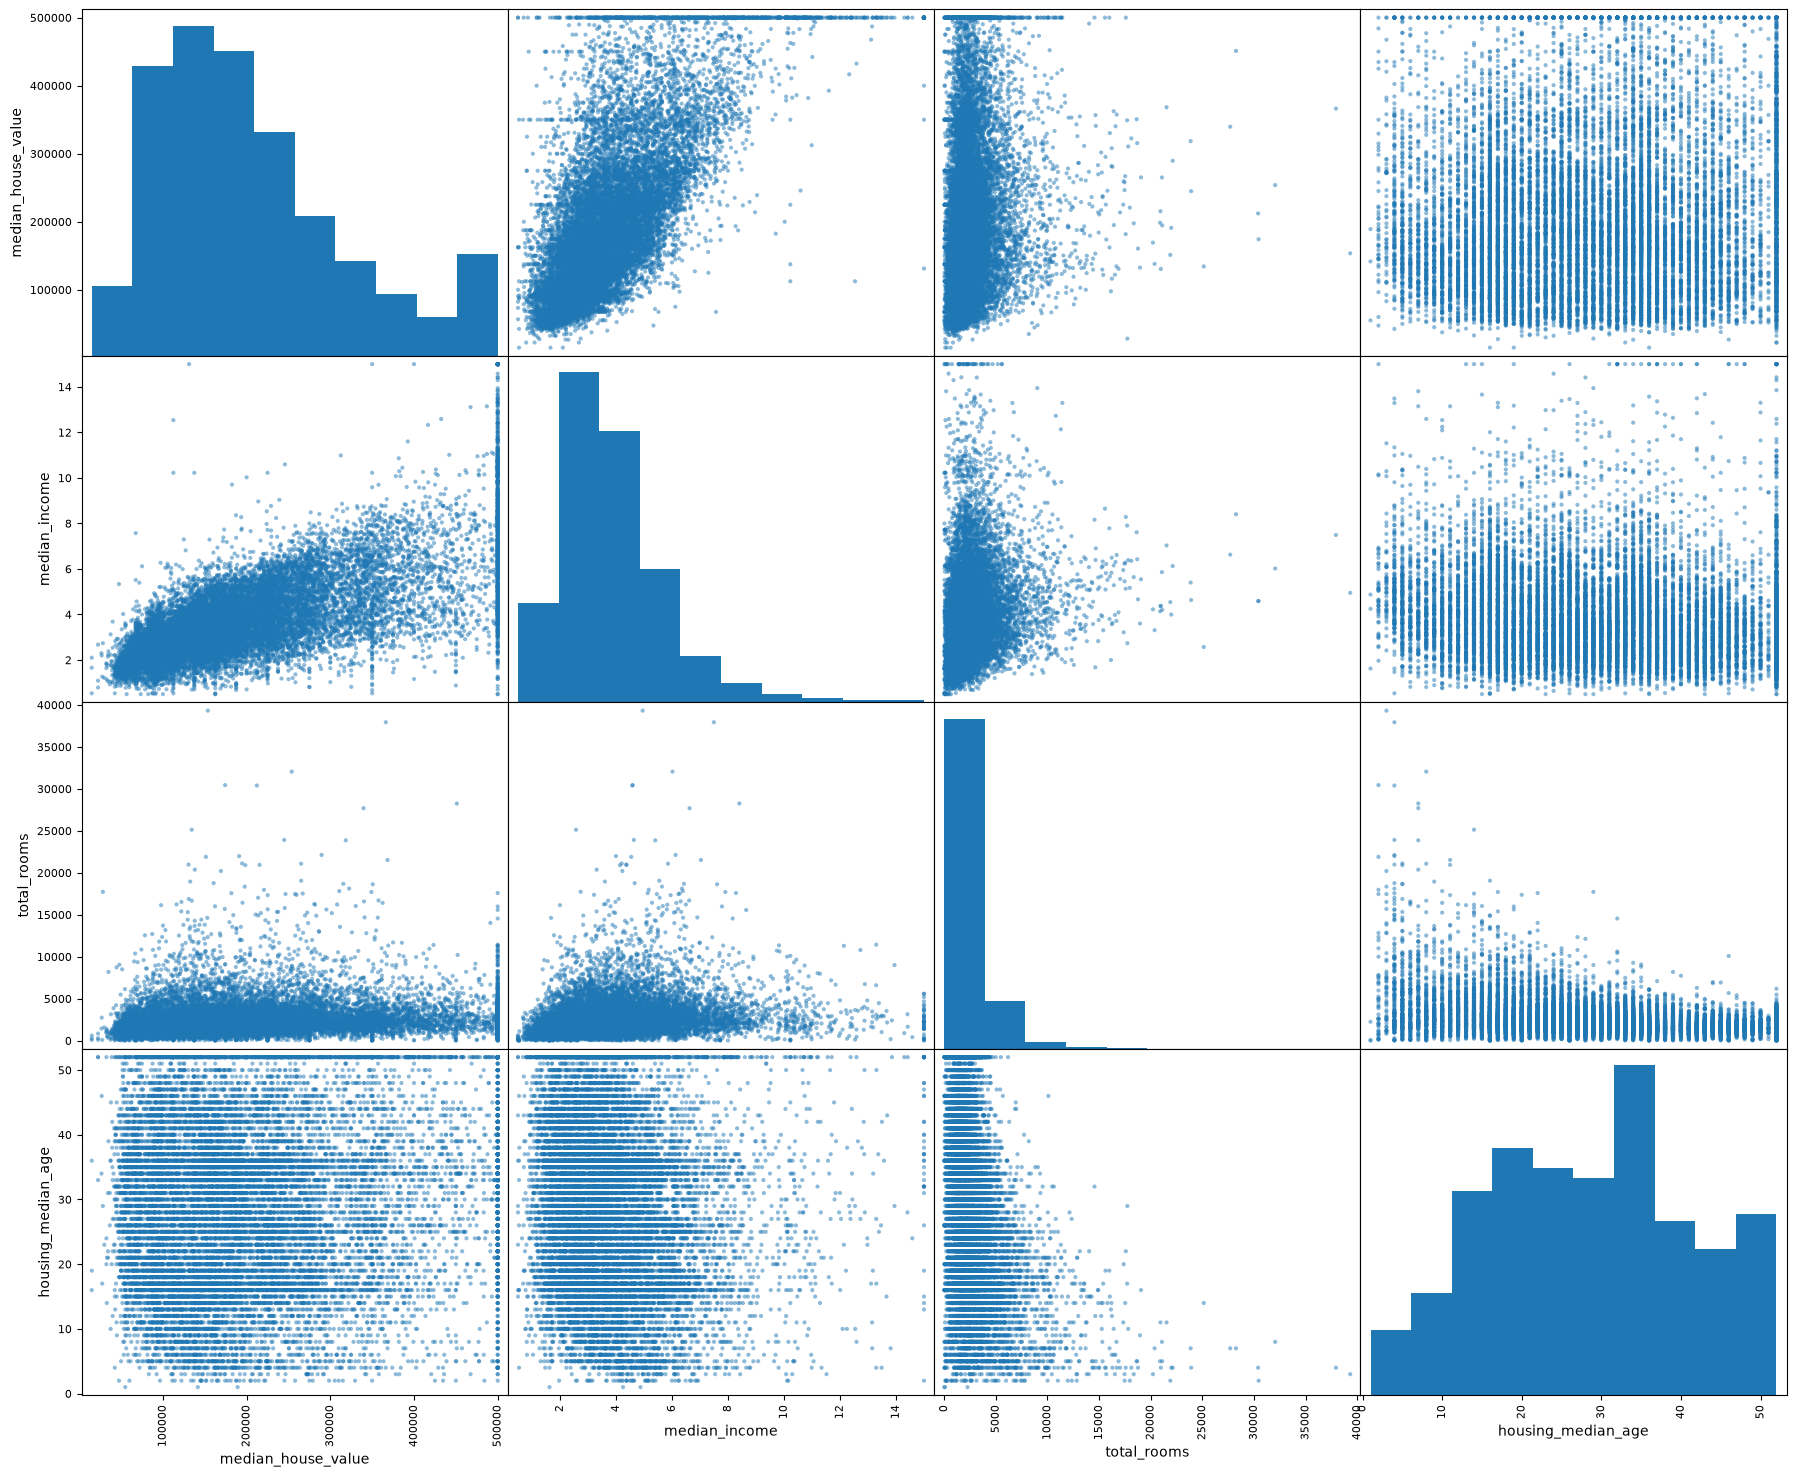

In [17]:
from pandas.plotting import scatter_matrix
attributes = ["median_house_value", "median_income", "total_rooms", "housing_median_age"]
scatter_matrix(housing[attributes], figsize=(22, 18))

<Axes: xlabel='median_income', ylabel='median_house_value'>

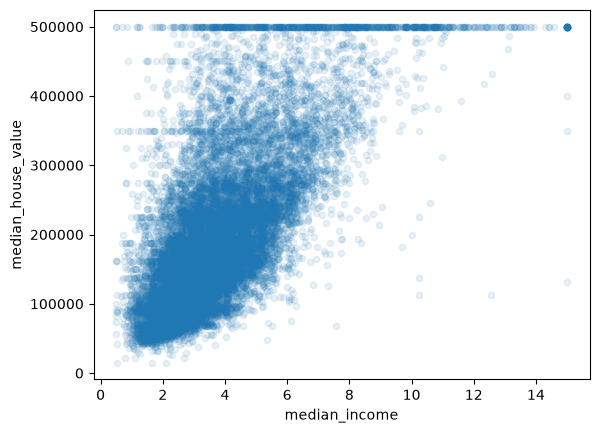

In [18]:
housing.plot(kind = "scatter", x="median_income", y="median_house_value", alpha=0.1) 

In [19]:
housing["rooms_per_household"] = housing["total_rooms"]/housing["households"]
housing["bedrooms_per_rooms"] = housing["total_bedrooms"]/housing["total_rooms"]
housing["population_per_house"] = housing["population"]/housing["households"]

In [20]:
corr_matrix = housing.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value      1.000000
median_income           0.687151
rooms_per_household     0.146255
total_rooms             0.135140
housing_median_age      0.114146
households              0.064590
total_bedrooms          0.047781
population_per_house   -0.021991
population             -0.026882
longitude              -0.047466
latitude               -0.142673
bedrooms_per_rooms     -0.259952
Name: median_house_value, dtype: float64

In [21]:
housing = strat_train_set.drop("median_house_value", axis = 1)
housing_labels = strat_train_set["median_house_value"].copy()

In [42]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy = "median")

#since the median can only be calculated on numerical atrributes therefore we will create a copy of that data without the text attribute ocean_proximity

housing_num = housing.drop("ocean_proximity", axis = 1)

#now fitting the imputer instance to the training data

imputer.fit(housing_num)
imputer.statistics_
#checking if the results are right or not
housing_num.median().values

#now let's use this "trained" imputer to transform the training set by replacing missing values with the learned medians
x = imputer.transform(housing_num)

#putting the plain array back pd dataframe
housing_tr = pd.DataFrame(x, columns=housing_num.columns)


       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0        -121.46     38.52                29.0       3873.0           797.0   
1        -117.23     33.09                 7.0       5320.0           855.0   
2        -119.04     35.37                44.0       1618.0           310.0   
3        -117.13     32.75                24.0       1877.0           519.0   
4        -118.70     34.28                27.0       3536.0           646.0   
...          ...       ...                 ...          ...             ...   
16507    -117.07     33.03                14.0       6665.0          1231.0   
16508    -121.42     38.51                15.0       7901.0          1422.0   
16509    -122.72     38.44                48.0        707.0           166.0   
16510    -122.70     38.31                14.0       3155.0           580.0   
16511    -122.14     39.97                27.0       1079.0           222.0   

       population  households  median_income  
0   